# Κ Proyecto Kappa | Predicción de Abandono de Clientes en Beta Bank

## Contexto empresarial

Beta Bank ha identificado un problema importante: cada mes una parte de sus clientes abandona la entidad financiera. La compañía sabe que retener clientes existentes suele ser considerablemente menos costoso que adquirir nuevos clientes, por lo que necesita una herramienta que permita identificar anticipadamente a los usuarios con mayor probabilidad de abandonar el banco.

Para abordar este problema, se desarrollará un modelo de Machine Learning capaz de predecir qué clientes presentan riesgo de cancelación utilizando información histórica sobre su comportamiento, características financieras y relación con la entidad.

El objetivo es proporcionar una solución predictiva que permita a Beta Bank implementar estrategias de retención más efectivas y reducir la pérdida de clientes.

## Objetivos

- Explorar y comprender el conjunto de datos.
- Preparar las variables para el entrenamiento de modelos predictivos.
- Analizar el equilibrio de clases de la variable objetivo.
- Entrenar modelos de clasificación para predecir el abandono de clientes.
- Evaluar el impacto del desbalance de clases sobre el rendimiento de los modelos.
- Aplicar diferentes técnicas para corregir el desequilibrio de clases.
- Optimizar hiperparámetros y seleccionar el modelo con mejor desempeño.
- Evaluar los modelos mediante las métricas F1 y ROC-AUC.
- Construir un modelo capaz de identificar clientes con riesgo de abandono.

## Conjunto de datos utilizado

- `Churn.csv`

## Variables disponibles

### Información del cliente

- `CustomerId`
- `Surname`
- `Age`
- `Gender`
- `Geography`

### Información financiera

- `CreditScore`
- `Balance`
- `EstimatedSalary`

### Relación con el banco

- `Tenure`
- `NumOfProducts`
- `HasCrCard`
- `IsActiveMember`

### Variable objetivo

- `Exited`
  - 1 = el cliente abandonó el banco.
  - 0 = el cliente permanece en el banco.

## Tipo de problema

**Clasificación supervisada binaria**

El modelo deberá predecir si un cliente:

- Permanece en el banco (0)
- Abandona el banco (1)

## Métricas de evaluación

### Métrica principal

```text
F1 Score
```

### Métrica complementaria

```text
ROC-AUC
```

## Criterio de éxito

Para cumplir los requisitos del proyecto:

```text
F1 ≥ 0.59
```

en el conjunto de prueba.

## Pregunta de negocio

**¿Es posible identificar anticipadamente a los clientes con mayor riesgo de abandonar Beta Bank utilizando información histórica sobre su comportamiento y características financieras?**

Primero analizaremos el dataset de forma general

In [ ]:
import pandas as pd

dataframe = pd.read_csv('/content/Churn (1).csv')

print(dataframe.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), object(3)
memory usage: 1.1+ MB
None


In [ ]:
print(dataframe.sample(8))

      RowNumber  CustomerId    Surname  CreditScore Geography  Gender  Age  \
7827       7828    15735968      Hsing          605    France    Male   41   
5841       5842    15737267    Marcelo          676    France  Female   49   
7367       7368    15736399    Korovin          606     Spain    Male   42   
4571       4572    15761775      Myers          598   Germany    Male   20   
5297       5298    15683416      Russo          572   Germany    Male   51   
9676       9677    15720924   Chijioke          585    France  Female   34   
5775       5776    15717527  Ifeanacho          619    France  Female   49   
4982       4983    15569120      Lucas          615    France    Male   30   

      Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
7827    10.0       0.00              2          0               1   
5841     1.0       0.00              1          1               0   
7367    10.0       0.00              2          1               0   
4571     8.0  180293.

In [ ]:
print(dataframe.isna().sum())

RowNumber            0
CustomerId           0
Surname              0
CreditScore          0
Geography            0
Gender               0
Age                  0
Tenure             909
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
dtype: int64


In [ ]:
print(dataframe.duplicated().sum())

0


Analizando el dataset nos pudimos dar cuenta que hasta el momento la única anomalía podría ser la columna de Tenure, la cual contiene el período durante el cual ha madurado el depósito a plazo fijo de un cliente en años. Por lo que analizaremos un poco más a detalle esa columna en solitario.

In [ ]:
print(dataframe["Tenure"].sample(20))
print()
print()
print(dataframe["Tenure"].describe())
print()
print()
print(dataframe["Tenure"].value_counts().sort_index())

5655    1.0
2454    1.0
3523    6.0
4484    NaN
4769    1.0
2995    2.0
4756    1.0
9728    7.0
9877    3.0
622     5.0
6763    7.0
8105    2.0
5403    NaN
557     3.0
6061    5.0
6437    4.0
3037    1.0
8381    2.0
3655    6.0
8426    1.0
Name: Tenure, dtype: float64


count    9091.000000
mean        4.997690
std         2.894723
min         0.000000
25%         2.000000
50%         5.000000
75%         7.000000
max        10.000000
Name: Tenure, dtype: float64


Tenure
0.0     382
1.0     952
2.0     950
3.0     928
4.0     885
5.0     927
6.0     881
7.0     925
8.0     933
9.0     882
10.0    446
Name: count, dtype: int64


Analizando mejor esta columna nos damos cuenta que tanto la media la cual es de 4.997690 y que podemos redondear a 5 es muy similar al valor de 5 años de la mediana 5.000000 que tambien redondeamos a 5.

Esto nos indica que la distribución de los datos está bastante equilibrada al rededor del centro.

Con esto en mente se tomó la decisión de reemplazar los valores NaN faltantes de esta columna con la media/mediana de los datos, ya que al ser el valor más frecuente puede introducir menos sesgo artificial y alteraría lo menos posible los datos originales.

In [ ]:
dataframe["Tenure"] = dataframe["Tenure"].fillna(dataframe["Tenure"].median())
print(dataframe["Tenure"].isna().sum())

0


Ahora podemos analizar el desequilibrio de clases de la variable objetivo que en este proyecto es Exited

Exited
0    7963
1    2037
Name: count, dtype: int64


Exited
0    79.63
1    20.37
Name: proportion, dtype: float64
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


<Axes: xlabel='Exited'>

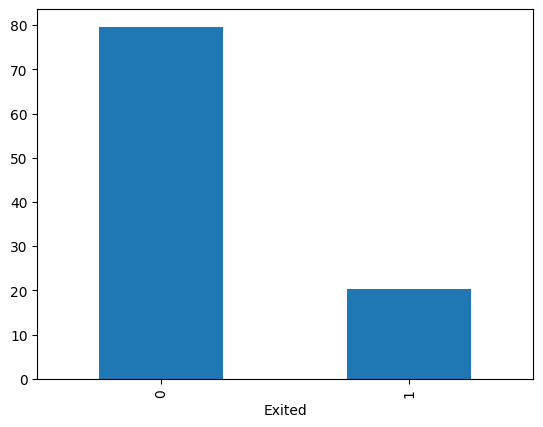

In [ ]:
print(dataframe["Exited"].value_counts())
print()
print()
print(dataframe["Exited"].value_counts(normalize = True) * 100)

desbalance_de_clases = dataframe["Exited"].value_counts(normalize = True) * 100

import matplotlib.pyplot as plt
print(desbalance_de_clases)
desbalance_de_clases.plot(kind = "bar")


Analizando esta sección podemos darnos cuenta que un 79.6% de los clientes permanecieron con nosotros, mientras que un 20.3% abandonaron el banco.

También podemos decir que claramente existe un desequillibrio de las clases moderada, y que por lo tanto nuestros modelos predictivos podrían encontrar obstáculos al intentar detectar la clase minoritaria que en este caso es para el tipo 1 (clientes que abandonaron el banco).

Ahora procederemos a analizar de nuevo el dataset

In [ ]:
print(dataframe.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), object(3)
memory usage: 1.1+ MB
None


Se analizaron de nuevo las columnas y se llegó a la conclusión de que es buena idea eliminar 3 columas las cuales son:

"CustomerId", "RowNumber", "Surname"

Esto ya que en el caso de CustomerId que se trata del identificador único de cliente no entra en la operación de aprendizaje donde se perciben patrones. de igual forma no es relevante para el modelo la columna Surname, ya que solo contiene los apellidos, esto además de que si aplicamos OneHotEncodging a esta columna obtendríamos muchas columnas innecesarias. Y para finalizar eliminamos también Rownumber porque se trata de otro identificador único que no aporta mucha información para los modelos

In [ ]:
dataframe_nuevo = dataframe.drop(["CustomerId", "RowNumber", "Surname"], axis = 1)
print(dataframe_nuevo.columns)
print(dataframe_nuevo.sample(5))

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited'],
      dtype='object')
      CreditScore Geography  Gender  Age  Tenure    Balance  NumOfProducts  \
3167          637    France  Female   48     7.0  130806.99              2   
2855          710     Spain  Female   75     5.0       0.00              2   
7699          605     Spain  Female   36     9.0       0.00              2   
5241          574    France    Male   41     1.0       0.00              2   
374           717   Germany    Male   35     7.0   58469.37              2   

      HasCrCard  IsActiveMember  EstimatedSalary  Exited  
3167          1               1        132005.85       1  
2855          1               1          9376.89       0  
7699          0               1         35521.63       0  
5241          0               0         70550.00       0  
374           1               1        172459.39 

De este nuevo dataset podemos ver que es necesario aplicar OHE a dos de las columnas que quedaron. Geography y Gender aplicando drop_first = True para evitar la trampa dummy en estas dos columnas.

In [ ]:
dataframe_limpio = pd.get_dummies(dataframe_nuevo, columns = ["Geography", "Gender"], drop_first = True)
print(dataframe_limpio.sample(4))
print(dataframe_limpio.info())

      CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
8265          618   40     0.0  140306.38              1          1   
1803          577   26     1.0  180530.51              1          0   
909           806   25     7.0       0.00              2          1   
874           645   38     5.0  101430.30              2          0   

      IsActiveMember  EstimatedSalary  Exited  Geography_Germany  \
8265               0        160618.61       1               True   
1803               0        123454.62       0              False   
909                0         18461.90       0              False   
874                1          4400.32       0              False   

      Geography_Spain  Gender_Male  
8265            False        False  
1803            False        False  
909              True         True  
874             False        False  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Colum

Ahora nos enforcaremos en definir las características y el objetivo

In [ ]:
target = dataframe_limpio["Exited"]
features = dataframe_limpio.drop(["Exited"], axis = 1)

Separaremos los datos en conjuntos de entrenamiento y validación y verificamos sus nuevas dimensiones

In [ ]:
from sklearn.model_selection import train_test_split

target_train, target_temp, features_train, features_temp = train_test_split(target, features, test_size = 0.4, random_state = 12345)

target_valid, target_test, features_valid, features_test = train_test_split(target_temp, features_temp, test_size = 0.5, random_state = 12345)

print(target_train.shape)
print(features_train.shape)
print(target_valid.shape)
print(features_valid.shape)
print(target_test.shape)
print(features_test.shape)

(6000,)
(6000, 11)
(2000,)
(2000, 11)
(2000,)
(2000, 11)


Ahora procederemos a probar el modelo de regresión logística primero pasando por un proceso de escalado de características

In [ ]:
from sklearn.preprocessing import StandardScaler

numeric = features_train.select_dtypes(include = ["int64", "float64"]).columns
scaler = StandardScaler()
scaler.fit(features_train[numeric])
features_train[numeric] = scaler.transform(features_train[numeric])
features_valid[numeric] = scaler.transform(features_valid[numeric])
features_test[numeric] = scaler.transform(features_test[numeric])


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

model_linear = LogisticRegression(random_state = 12345,  solver = "liblinear")

model_linear.fit(features_train, target_train)

predicted_valid_linear = model_linear.predict(features_valid)

f1 = f1_score(target_valid, predicted_valid_linear)

print("El valor F1 de la regresión logística es de: ", f1)



El valor F1 de la regresión logística es de:  0.3310810810810811


El área bajo la curva ROC es de: 0.7587588238496482


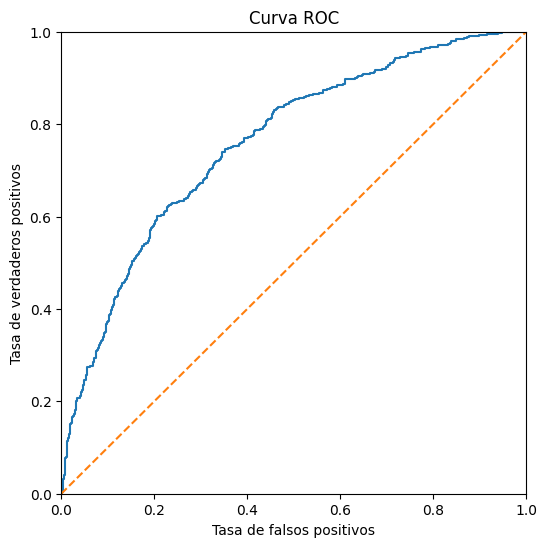

In [ ]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

probabilities_valid_linear = model_linear.predict_proba(features_valid)
probabilities_one_valid_linear = probabilities_valid_linear[:, 1]
auc_roc_linear = roc_auc_score(target_valid, probabilities_one_valid_linear)

print("El área bajo la curva ROC es de:", auc_roc_linear)

fpr, tpr, thresholds = roc_curve(target_valid, probabilities_one_valid_linear)

plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.ylabel('Tasa de verdaderos positivos')
plt.xlabel('Tasa de falsos positivos')
plt.title('Curva ROC')
plt.show()


Después de haber probado el modelo de regresión logística con un escalado de características se obtuvo un valor de F1 de 0.33. Este modelo fué probado en un test de validación sin tratar con el desequilibrio de clases.

También calculamos el area bajo la curva ROC y obtuvimos un valor de 0.75.

De estos dos valores podemos decir que al ser el AUC-ROC de 0.75 el modelo encuentra patrones y distingue razonablemente entre las dos clases.

Pero el valor F1 es bajo, de 0.33, por lo que podemos decir que el modelo todavía no detecta de forma aceptable los valores de clase positiva, es decir los clientes que abandonan.

Probaremos ahora con el modelo de arbol de decidión evaluando la mejor profundidad, su valor F1 y su valor AUC-ROC

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score

mejor_profundidad = 0
mejor_f1 = 0
mejor_modelo = None

for depth in range (1, 100):
    model_tree = DecisionTreeClassifier(max_depth = depth, random_state = 12345,)
    model_tree.fit(features_train, target_train)
    predicted_valid_tree = model_tree.predict(features_valid)
    f1_tree = f1_score(target_valid, predicted_valid_tree)

    if f1_tree > mejor_f1:
        mejor_profundidad = depth
        mejor_f1 = f1_tree
        mejor_modelo = model_tree

print("El mejor modelo de tipo árbol de desición es: ", mejor_modelo)
print("La mejor profundidad de los árboles es de: ", mejor_profundidad)
print("El mejor valor F1 del modelo es de: ", mejor_f1)

El mejor modelo de tipo árbol de desición es:  DecisionTreeClassifier(max_depth=6, random_state=12345)
La mejor profundidad de los árboles es de:  6
El mejor valor F1 del modelo es de:  0.5696969696969697


El valor AUC-SCORE del árbol de decisión es de:  0.6837644190927842


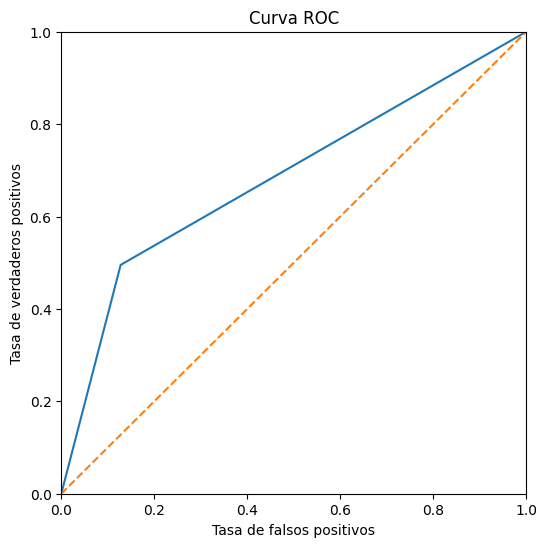

In [ ]:
probabilities_valid_tree = model_tree.predict_proba(features_valid)
probabilities_one_valid_tree = probabilities_valid_tree[:, 1]
auc_roc_tree = roc_auc_score(target_valid, probabilities_one_valid_tree)
print("El valor AUC-SCORE del árbol de decisión es de: ", auc_roc_tree)

fpr, tpr, thresholds = roc_curve(target_valid, probabilities_one_valid_tree)

plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.ylabel('Tasa de verdaderos positivos')
plt.xlabel('Tasa de falsos positivos')
plt.title('Curva ROC')
plt.show()

Analizando estos nuevos resultados, podemos ver que este modelo de árbol de decisión obtuvo una mejor puntuación F1, de 0.56. Esto nos indica que reconoce mejor los valores de clase positiva comparado con el modelo de regresión logística, llegando casi al valor que exige el proyecto (0.59), pero su AUC-ROC es bajo si lo comparamos con el modelo de regresión, esto nos indica que presenta una capacidad inferior para ordenar las clases.

Por último, construiremos un modelo de bosque aleatorio y de la misma forma vamos a calcular su valor F1 y su AUC-ROC tomando en cuenta además la mejor configuración de hiperparámetros como la cantidad de árboles y su profundidad.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

mejor_modelo = None
mejor_cantidad_de_arboles = 0
mejor_profundidad = 0
mejor_valor_F1 = 0

for depth in range(1, 20, 2):
    for n_estimators in range(100, 800, 200):
        model_forest = RandomForestClassifier(random_state = 12345, max_depth = depth, n_estimators = n_estimators, n_jobs = -1)
        model_forest.fit(features_train, target_train)
        predicted_valid_forest = model_forest.predict(features_valid)
        f1_score_forest = f1_score(target_valid, predicted_valid_forest)

        if f1_score_forest > mejor_valor_F1:
            mejor_modelo = model_forest
            mejor_cantidad_de_arboles = n_estimators
            mejor_profundidad = depth
            mejor_valor_F1 = f1_score_forest

print("El mejor modelo de árbol de decisión es: ", mejor_modelo)
print("La mejor profundidad de los árboles es de: ", mejor_profundidad)
print("El mejor valor F1 del modelo es de: ", mejor_valor_F1)
print("La mejor cantidad de árboles es de: ", mejor_cantidad_de_arboles)


El mejor modelo de árbol de decisión es:  RandomForestClassifier(max_depth=15, n_estimators=300, n_jobs=-1,
                       random_state=12345)
La mejor profundidad de los árboles es de:  15
El mejor valor F1 del modelo es de:  0.5894736842105263
La mejor cantidad de árboles es de:  300


El valor AUC-ROC del bosque aleatorio es de:  0.8438518863530508


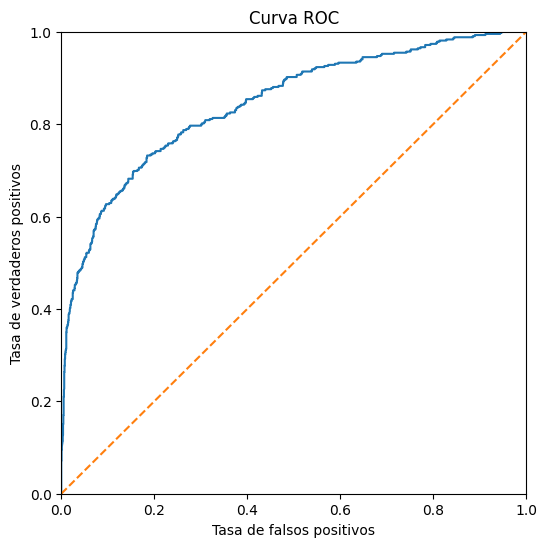

In [ ]:
predicted_valid_forest = model_forest.predict_proba(features_valid)
predicted_valid_one_forest = predicted_valid_forest[:, 1]
auc_score_forest = roc_auc_score(target_valid, predicted_valid_one_forest)
print("El valor AUC-ROC del bosque aleatorio es de: ", auc_score_forest)

fpr, tpr, thresholds = roc_curve(target_valid, predicted_valid_one_forest,)

plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.ylabel('Tasa de verdaderos positivos')
plt.xlabel('Tasa de falsos positivos')
plt.title('Curva ROC')
plt.show()

In [ ]:
datos = {"Modelo": ["Regresión logística", "Árbol de decisión", "Bosque aleatorio"],
         "Valor F1": [0.3310810810810811, 0.5696969696969697, 0.5894736842105263],
         "Valor de AUC_ROC": [0.7587588238496482, 0.6837644190927842, 0.8438518863530508]}

evaluacion_de_modelos = pd.DataFrame(datos)

print(evaluacion_de_modelos)

                Modelo  Valor F1  Valor de AUC_ROC
0  Regresión logística  0.331081          0.758759
1    Árbol de decisión  0.569697          0.683764
2     Bosque aleatorio  0.589474          0.843852


Con este último modelo podemos decir que el bosque aleatorio ha sido el que mejores métricas de evaluación ha obtenido hasta ahora con un valor F1 de 0.58 y un valor AUC_ROC de 0.84.

La construcción de estos 3 modelos fué ejecutada sin tratar con el desequilibrio de clases de la variable predictora (Exited).

No es de sorprendernos que con un posterior ajuste de clases los valores tanto de F1 como de AUC_ROC puedan aumentar considarablemente.

Para finalizar este análisis trabajaremos el equilibrio de clases ya mencionado partiendo del modelo de Bosque aleatorio con los hiperparámetros que evaluamos.

Antes de continuar debemos recordar el desequilibrio de las clases de nuestra variable predictora

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


<Axes: xlabel='Exited'>

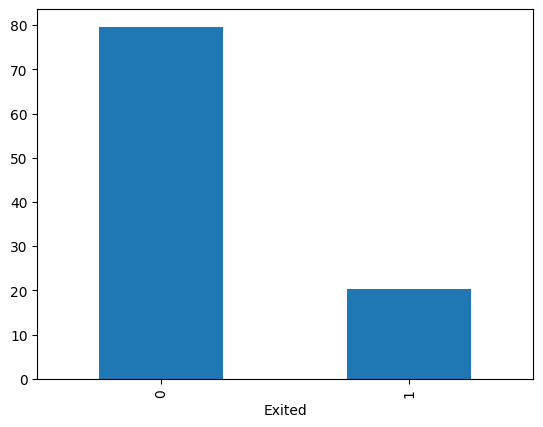

In [ ]:
desequilibrio_de_clases = dataframe["Exited"].value_counts(normalize = True) * 100
print(desequilibrio_de_clases)

desequilibrio_de_clases.plot(kind = "bar")

Observando que la clase que se presenta en menor cantidad es la clase 1, es decir, los clientes que abandonan el banco vamos a empezar por ejecutar un sobremuestreo de esta clase minoritaria y entrenaremos de nuevo el mejor modelo probado.

In [ ]:
from sklearn.utils import resample
from sklearn.utils import shuffle

df_train = features_train.copy()
df_train["Exited"] = target_train

print(df_train.info())

target_class_0 = df_train[df_train["Exited"] == 0]
target_class_1 = df_train[df_train["Exited"] == 1]

print()
print()

print(target_class_0["Exited"])
print()
print()
print(target_class_1["Exited"])

print()
print()


df_class_1_upsampled = resample(target_class_1, replace = True, random_state = 12345, n_samples = len(target_class_0))

print("Información de la nueva columna sobremuestreada")
print(df_class_1_upsampled["Exited"].info())

df_train_upsampled = pd.concat([df_class_1_upsampled, target_class_0])

print()
print()


df_train_upsampled = shuffle(df_train_upsampled, random_state = 12345)

print(df_train_upsampled.sample(5))

target_train_upsampled = df_train_upsampled["Exited"]
features_train_upsampled = df_train_upsampled.drop(["Exited"], axis = 1)

<class 'pandas.core.frame.DataFrame'>
Index: 6000 entries, 7479 to 4578
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CreditScore        6000 non-null   float64
 1   Age                6000 non-null   float64
 2   Tenure             6000 non-null   float64
 3   Balance            6000 non-null   float64
 4   NumOfProducts      6000 non-null   float64
 5   HasCrCard          6000 non-null   float64
 6   IsActiveMember     6000 non-null   float64
 7   EstimatedSalary    6000 non-null   float64
 8   Geography_Germany  6000 non-null   bool   
 9   Geography_Spain    6000 non-null   bool   
 10  Gender_Male        6000 non-null   bool   
 11  Exited             6000 non-null   int64  
dtypes: bool(3), float64(8), int64(1)
memory usage: 486.3 KB
None


7479    0
3411    0
6027    0
1247    0
3716    0
       ..
4478    0
4094    0
3492    0
2177    0
4578    0
Name: Exited, Length: 4804, dtype: int64


90

<Axes: xlabel='Exited'>

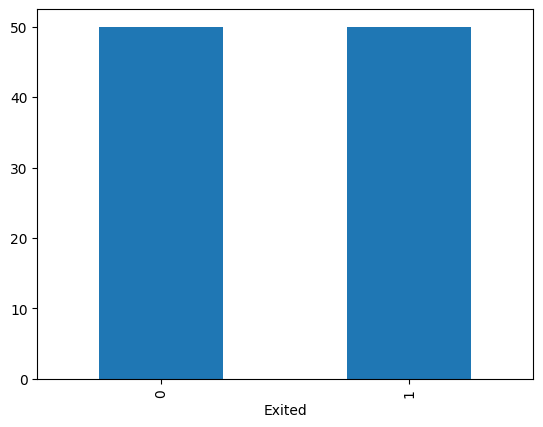

In [ ]:
equilibrio_de_clases = df_train_upsampled["Exited"].value_counts(normalize = True) * 100
equilibrio_de_clases.plot(kind = "bar")

En este momento y después de haber confirmado que se ejecutó correctamente el sobremuestreo de la clase minoritaria procederemos a entrenar nuevamente el modelo de bosque aleatorio y comprobaremos su nuevo valor F1, su graficación de curva roc con su respectivo valor y su valor AUC-ROC final.

El nuevo valor F1 es de:  0.6127770534550195
El nuevo valor AUC-ROC es de:  0.8433626806356196


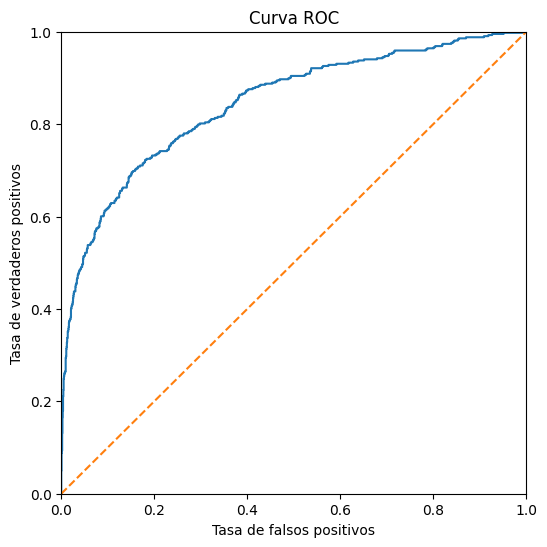

In [ ]:
model_forest_upsampled = RandomForestClassifier(max_depth = 15, n_estimators = 300, random_state = 12345, n_jobs = -1)
model_forest_upsampled.fit(features_train_upsampled, target_train_upsampled)
new_predicted_valid_f1 = model_forest_upsampled.predict(features_valid)
new_predicted_valid = model_forest_upsampled.predict_proba(features_valid)
new_predicted_valid_class_1 = new_predicted_valid[:, 1]
new_f1_score = f1_score(target_valid, new_predicted_valid_f1)
print("El nuevo valor F1 es de: ", new_f1_score)


new_auc_roc = roc_auc_score(target_valid, new_predicted_valid_class_1)
print("El nuevo valor AUC-ROC es de: ", new_auc_roc)

fpr, tpr, thresholds = roc_curve(target_valid, new_predicted_valid_class_1)

plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.ylabel('Tasa de verdaderos positivos')
plt.xlabel('Tasa de falsos positivos')
plt.title('Curva ROC')
plt.show()

Con este nuevo resultado podemos observar que el valor F1 en este caso superó los requerimientos del proyecto con un puntaje de 0.6127770534550195. Esta mejorda se vió favorecida por el sobremuestreo que busca equilibrar las clases de la variable objetivo, por lo que podemos decir que la capacidad de detectar los valores positivos se vió aumentada.

Por otro lado, el valor AUC-ROC no experimentó gran cambio respecto a su valor original. Esto nos indica que la capacidad de separación de clases permanece prácticamente constante.

Cantidad original de observaciones por clase:
Clase 0: 4804
Clase 1: 1196

Cantidad de observaciones después del submuestreo:
Exited
1    1196
0    1196
Name: count, dtype: int64

Proporciones después del submuestreo:
Exited
1    0.5
0    0.5
Name: proportion, dtype: float64

El valor F1 con submuestreo es de: 0.5819209039548022
El valor ROC-AUC con submuestreo es de: 0.8461708877987406


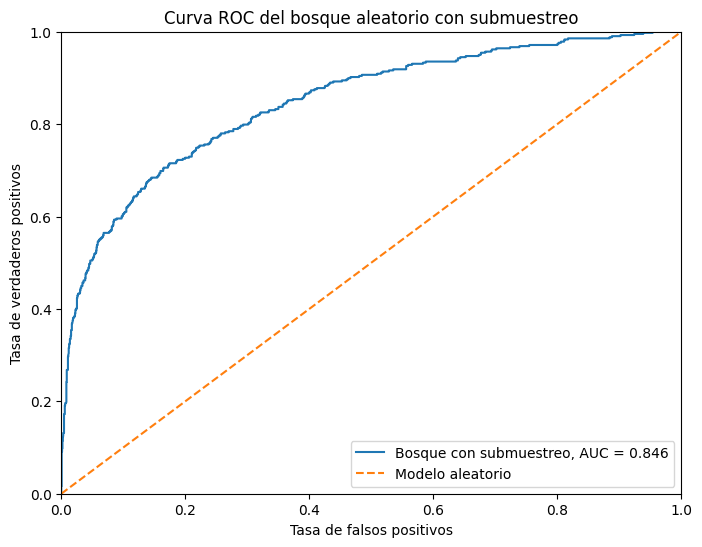

In [ ]:
df_train_downsampled = features_train.copy()

df_train_downsampled["Exited"] = target_train


df_class_0 = df_train_downsampled[
    df_train_downsampled["Exited"] == 0
]

df_class_1 = df_train_downsampled[
    df_train_downsampled["Exited"] == 1
]



print("Cantidad original de observaciones por clase:")

print("Clase 0:", len(df_class_0))
print("Clase 1:", len(df_class_1))



df_class_0_downsampled = resample(
    df_class_0,
    replace=False,
    n_samples=len(df_class_1),
    random_state=12345
)



df_train_downsampled = pd.concat(
    [
        df_class_0_downsampled,
        df_class_1
    ]
)



df_train_downsampled = shuffle(
    df_train_downsampled,
    random_state=12345
)



features_train_downsampled = df_train_downsampled.drop(
    columns=["Exited"]
)

target_train_downsampled = df_train_downsampled["Exited"]



print("\nCantidad de observaciones después del submuestreo:")

print(
    target_train_downsampled.value_counts()
)

print("\nProporciones después del submuestreo:")

print(
    target_train_downsampled.value_counts(normalize=True)
)



model_forest_downsampled = RandomForestClassifier(
    max_depth=15,
    n_estimators=300,
    random_state=12345,
    n_jobs=-1
)

model_forest_downsampled.fit(
    features_train_downsampled,
    target_train_downsampled
)



predicted_valid_downsampled = model_forest_downsampled.predict(
    features_valid
)

f1_downsampled = f1_score(
    target_valid,
    predicted_valid_downsampled
)

print(
    "\nEl valor F1 con submuestreo es de:",
    f1_downsampled
)



probabilities_valid_downsampled = (
    model_forest_downsampled.predict_proba(features_valid)
)

probabilities_one_valid_downsampled = (
    probabilities_valid_downsampled[:, 1]
)

auc_roc_downsampled = roc_auc_score(
    target_valid,
    probabilities_one_valid_downsampled
)

print(
    "El valor ROC-AUC con submuestreo es de:",
    auc_roc_downsampled
)



fpr_downsampled, tpr_downsampled, thresholds_downsampled = roc_curve(
    target_valid,
    probabilities_one_valid_downsampled
)



plt.figure(figsize=(8, 6))

plt.plot(
    fpr_downsampled,
    tpr_downsampled,
    label=f"Bosque con submuestreo, AUC = {auc_roc_downsampled:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Modelo aleatorio"
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC del bosque aleatorio con submuestreo")

plt.legend()
plt.show()

El submuestreo produjo un F1 de 0.582 y un ROC-AUC de 0.846. Aunque esta técnica obtuvo el ROC-AUC más alto entre los enfoques evaluados, su valor F1 fue inferior al del modelo sin balanceo y al del modelo con sobremuestreo. Esta reducción puede estar relacionada con la pérdida de información causada al disminuir la cantidad de observaciones de la clase mayoritaria. Debido a que F1 es la métrica principal del proyecto, se selecciona el bosque aleatorio entrenado mediante sobremuestreo, que alcanzó un F1 de 0.613 y un ROC-AUC de 0.843.

Modelo final (Bosque aleatorio)

In [ ]:
predicted_final_bosquef1 = model_forest_upsampled.predict(features_test)
predicted_final_bosque = model_forest_upsampled.predict_proba(features_test)
predicted_final_bosqueauc = predicted_final_bosque[:, 1]


valor_f1_final = f1_score(target_test, predicted_final_bosquef1)

auc_score_final = roc_auc_score(target_test, predicted_final_bosqueauc)

print("El valor F1 final para el modelo en el test de prueba es de:", valor_f1_final)
print()
print()
print("El valor del área bajo la curva ROC final para el modelo en el test de prueba es de:", auc_score_final)

El valor F1 final para el modelo en el test de prueba es de: 0.6010498687664042


El valor del área bajo la curva ROC final para el modelo en el test de prueba es de: 0.8553055072098772


Después de comparar los modelos de regresión logística, árbol de decisión y bosque aleatorio, se seleccionó el bosque aleatorio por obtener el mejor desempeño general. Posteriormente, se aplicaron las técnicas de sobremuestreo y submuestreo para reducir el efecto del desequilibrio de clases.

El sobremuestreo produjo el mejor valor F1 en el conjunto de validación, por lo que se seleccionó el bosque aleatorio entrenado con esta técnica como modelo final. En el conjunto de prueba, el modelo alcanzó un valor F1 de 0.601 y un ROC-AUC de 0.855. El valor F1 supera el mínimo requerido de 0.59, mientras que el ROC-AUC indica una buena capacidad para distinguir entre clientes que abandonan el banco y clientes que permanecen.

La diferencia entre los resultados de validación y prueba fue pequeña, lo que sugiere que el modelo mantiene un desempeño estable ante datos no utilizados durante su entrenamiento y selección.